# In-class work 9. Optimising setpoints

Industrial AI, KBTU. Goes with Lecture 9, "Optimization task with machine learning
algorithms".

The object is a belt dryer. Wet granules ride on a belt for 15 minutes while hot air blows
through them. The operator sets two numbers: the inlet air temperature $T$ (°C) and the air flow
$Q$ (kg/s). The customer accepts at most 3.0 % moisture, and the plant pays for every kilowatt of
the burner and the fan.

The operators run 110 °C and 8 kg/s, and the product is always in spec. Today we find out what
"always in spec" costs, and how to find cheaper setpoints without breaking the spec.

| part | content |
|---|---|
| 1 | the dryer and the map of the problem |
| 2 | the problem in four pieces, KKT, SLSQP |
| 3 | Nelder–Mead and the penalty |
| 4 | differential evolution |
| 5 | a third setpoint: equal budgets, a local optimum |
| 6 | no simulator: a surrogate of the historian, the trust region |
| 7 | the safety margin |

Parts 1–5 use a simulator, so every answer can be checked against the truth. Part 6 takes it
away, as on a real plant. Run top to bottom with `Shift+Enter`; it takes about a minute.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import scipy
import sklearn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


---

# Part 1. The dryer

## 1.1 The simulator

On a real plant nobody hands you this function. Here it is written out, so that you can see
what the optimiser is up against.

- The water removed is the smaller of two limits. Kinetics: $k \propto e^{-5000/T_K}\sqrt{Q}$,
  so hotter air dries faster. Heat: evaporating a kilogram of water takes 2400 kJ, and the air
  gives only the heat it carries above about 55 °C.
- The power is the burner (from 20 °C to $T$, efficiency 0.88), the wall losses, and the fan,
  which grows as $Q^3$.
- `m_in` is the feed moisture, 25 % on average. It drifts from day to day and nobody controls it.
- `r` is the share of exhaust air sent back to the burner. The damper stays closed ($r = 0$)
  until Part 5.

In [2]:
CP, T_AMB, LATENT = 1.01, 20.0, 2400.0     # air kJ/(kg K), ambient °C, water kJ/kg
FEED_DRY, TAU = 0.5, 900.0                 # dry solids kg/s, time on the belt s
SPEC = 3.0                                 # the most moisture the customer accepts, %


def dryer(T, Q, m_in=25.0, r=0.0):
    # Outlet moisture (%) and power (kW) at steady state.
    # T in °C, Q in kg/s; arrays work too.
    T, Q = np.asarray(T, float), np.asarray(Q, float)

    # drying rate, 1/s
    k = 1.5e3 * np.exp(-5000 / (T + 273.15)) * np.sqrt(Q / 6) * (1 - r)
    # water the granules can give, kg/s, and water the air can take, kg/s
    by_kinetics = FEED_DRY * m_in / 100 * (1 - np.exp(-k * TAU))
    by_heat = np.maximum(Q * CP * (T - 55 - 40 * r), 1e-6) / LATENT
    # the smaller of the two, smoothed
    water = (by_kinetics ** -4 + by_heat ** -4) ** -0.25
    moisture = m_in - 100 * water / FEED_DRY

    # recirculated air enters the burner warmer than the ambient air
    T_exhaust = T - water * LATENT / (Q * CP)
    T_burner_in = T_AMB + r * (T_exhaust - T_AMB)
    power = (Q * CP * (T - T_burner_in) + 3.0 * (T - T_AMB)) / 0.88 + 0.08 * Q ** 3
    return moisture, power


m0, p0 = dryer(110, 8)
print(f"operators' setpoints 110 °C, 8 kg/s: moisture {m0:.2f} %, power {p0:.0f} kW")

operators' setpoints 110 °C, 8 kg/s: moisture 1.85 %, power 1174 kW


The product leaves at 1.85 % while 3.0 % is allowed. The operators over-dry, and they pay for it
in gas.

## 1.2 The map

Colour is the power, the red line is moisture = 3.0 %, the hatched area is out of spec. We find
the cheapest point in spec by brute force on a 500 × 500 grid, a quarter of a million
evaluations. On a real dryer one evaluation is an hour of production, so only a simulator can
afford this map.

cheapest point in spec: T = 131.5 °C, Q = 4.35 kg/s, moisture 3.00 %, power 943 kW
the operators pay 232 kW more, 20% of their bill


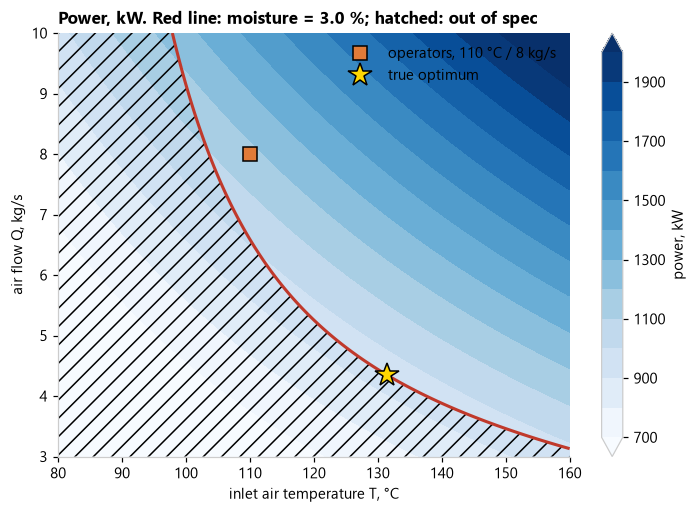

In [3]:
T_LO, T_HI, Q_LO, Q_HI = 80, 160, 3, 10
tg, qg = np.meshgrid(np.linspace(T_LO, T_HI, 500), np.linspace(Q_LO, Q_HI, 500))
M_map, P_map = dryer(tg, qg)

# the grid point with the least power among those in spec
in_spec_power = np.where(M_map <= SPEC, P_map, np.inf)
i = np.argmin(in_spec_power)
T_best, Q_best, P_best = tg.flat[i], qg.flat[i], P_map.flat[i]
print(f"cheapest point in spec: T = {T_best:.1f} °C, Q = {Q_best:.2f} kg/s, "
      f"moisture {M_map.flat[i]:.2f} %, power {P_best:.0f} kW")
extra = p0 - P_best
print(f"the operators pay {extra:.0f} kW more, {extra / p0:.0%} of their bill")


def draw_map(ax, title=""):
    power_levels = np.arange(700, 2001, 100)
    cs = ax.contourf(tg, qg, P_map, levels=power_levels, cmap="Blues", extend="both")
    ax.contour(tg, qg, M_map, levels=[SPEC], colors=RED, linewidths=2)
    ax.contourf(tg, qg, M_map, levels=[SPEC, 100], colors="none", hatches=["//"])
    ax.plot(110, 8, "s", color=ORANGE, ms=9, mec="black",
            label="operators, 110 °C / 8 kg/s")
    ax.plot(T_best, Q_best, "*", color="gold", ms=16, mec="black", label="true optimum")
    ax.set(xlabel="inlet air temperature T, °C", ylabel="air flow Q, kg/s")
    ax.grid(False)
    if title:
        ax.set_title(title, fontsize=11)
    return cs


fig, ax = plt.subplots(figsize=(7.5, 5))
cs = draw_map(ax, "Power, kW. Red line: moisture = 3.0 %; hatched: out of spec")
fig.colorbar(cs, ax=ax, label="power, kW")
ax.legend(loc="upper right")
plt.show()

Three things on this map hold for almost every setpoint problem.

- The optimum sits on the constraint. Over-drying costs energy, so an answer well inside the
  spec can still be improved.
- The valley along the red line is flat: from 125 to 145 °C the power changes by a few percent.
  Many setpoints are almost equally good, and the methods below stop at slightly different
  places along the valley for that reason.
- Hotter air with less flow is cheaper, until the flow is too small to carry the water away.
  Then the moisture shoots up. That edge is the red line.

---

# Part 2. The problem in four pieces

| piece | here | in code |
|---|---|---|
| decision variables $\mathbf{x}$ | $T$, $Q$ | `x = [T, Q]` |
| bounds | $80 \le T \le 160$, $3 \le Q \le 10$ | `bounds=[(80, 160), (3, 10)]` |
| objective $f(\mathbf{x})$, minimised | power, kW | `power(x)` |
| constraint $g(\mathbf{x}) \ge 0$ | $3.0 - M(\mathbf{x}) \ge 0$ | `spec_margin(x)` |

`scipy.optimize` has two kinds of methods.

- Local ones, `minimize(f, x0, method=...)`, walk downhill from $\mathbf{x}_0$. They are cheap
  and find the nearest valley.
- Global ones, such as `differential_evolution(f, bounds)`, spread a population over the box.
  They need many more calls and depend little on the start.

## 2.1 What holds at the optimum

$$\min_{\mathbf{x}} f(\mathbf{x}) \quad \text{subject to} \quad g(\mathbf{x}) \ge 0, \quad \mathbf{l} \le \mathbf{x} \le \mathbf{u}; \qquad \mathcal{L}(\mathbf{x}, \lambda) = f(\mathbf{x}) - \lambda\, g(\mathbf{x}).$$

At an optimum away from the edges of the box the **KKT conditions** hold:

$$\nabla f(\mathbf{x}^*) = \lambda\, \nabla g(\mathbf{x}^*), \qquad g(\mathbf{x}^*) \ge 0, \qquad \lambda \ge 0, \qquad \lambda\, g(\mathbf{x}^*) = 0.$$

- If $g > 0$, the constraint is slack: $\lambda = 0$ and $\nabla f = \mathbf{0}$, an ordinary
  minimum inside the spec.
- If $g = 0$, the constraint is active and the two gradients are parallel. On the map a power
  contour just touches the red line. If the contour crossed the line instead, you could slide
  along the line towards lower power, so the point would not be optimal.
- $\lambda$ is in kW per % of moisture: the power saved if the spec were relaxed by 1 %. It is
  called the **shadow price** of the constraint.

## 2.2 One iteration of SLSQP

SLSQP keeps $\mathbf{B}_k$, its estimate of the second derivatives of $\mathcal{L}$, starting
from $\mathbf{B}_0 = \mathbf{I}$.

| step | formula |
|---|---|
| 1. slopes by finite differences | $\partial f / \partial x_i \approx \bigl(f(\mathbf{x}_k + h\,\mathbf{e}_i) - f(\mathbf{x}_k)\bigr) / h$, $h \approx 1.5 \cdot 10^{-8}$ |
| 2. quadratic subproblem, solved exactly | $\min_{\mathbf{d}}\ \nabla f_k^{\top} \mathbf{d} + \frac{1}{2} \mathbf{d}^{\top} \mathbf{B}_k \mathbf{d}$ s.t. $g_k + \nabla g_k^{\top} \mathbf{d} \ge 0$ |
| 3. step length on the true functions | $\mathbf{x}_{k+1} = \mathbf{x}_k + \alpha\, \mathbf{d}_k$; $\alpha$ is cut until $f + \rho \max(0, -g)$ drops, $\rho \ge \lambda$ |
| 4. curvature update (BFGS) | $\mathbf{B}_{k+1} = \mathbf{B}_k - \dfrac{\mathbf{B}_k \mathbf{s} \mathbf{s}^{\top} \mathbf{B}_k}{\mathbf{s}^{\top} \mathbf{B}_k \mathbf{s}} + \dfrac{\mathbf{y} \mathbf{y}^{\top}}{\mathbf{y}^{\top} \mathbf{s}}$ |

Here $\mathbf{s} = \mathbf{x}_{k+1} - \mathbf{x}_k$ and $\mathbf{y}$ is the change of
$\nabla_{\mathbf{x}} \mathcal{L}$ over the step.

In pictures: at every iterate SLSQP replaces the power by a bowl and the red line by a straight
line through the current point, jumps to the bottom of the bowl on the good side of that line,
and then checks the jump on the real dryer. $\mathbf{B}_k$ is the shape of the bowl. It starts
round and learns the true curvature from how the slopes changed along each step. Once it has,
each step is close to a Newton step and the error shrinks fast.

`Counter` counts the calls to the plant, so that methods can be compared fairly. The last lines
of the cell check KKT: the slope of $P$ divided by the slope of $g$, along $T$ and along $Q$. At
the optimum both ratios must equal $\lambda$.

In [4]:
from scipy.optimize import minimize, differential_evolution

BOUNDS = [(T_LO, T_HI), (Q_LO, Q_HI)]


class Counter:
    # Wraps a function of x, counts the calls and keeps every x it saw, in order.
    def __init__(self, fun):
        self.fun, self.calls, self.xs = fun, 0, []

    def __call__(self, x):
        self.calls += 1
        self.xs.append(np.array(x, float))
        return self.fun(x)


def power(x):
    return float(dryer(x[0], x[1])[1])


def spec_margin(x):                      # >= 0 means in spec
    return SPEC - float(dryer(x[0], x[1])[0])


f_slsqp = Counter(power)
res = minimize(f_slsqp, x0=[110, 8], method="SLSQP", bounds=BOUNDS,
               constraints=[{"type": "ineq", "fun": spec_margin}])
print(f"SLSQP from the operators' point: T = {res.x[0]:.1f} °C, Q = {res.x[1]:.2f} kg/s, "
      f"power {res.fun:.0f} kW, moisture {SPEC - spec_margin(res.x):.2f} %")
print(f"calls to power(): {f_slsqp.calls}  (the constraint was called separately)\n")


def grad(fun, x, h=1e-5):
    # central differences, for the check only
    x = np.asarray(x, float)
    steps = np.eye(len(x))
    return np.array([(fun(x + h * e) - fun(x - h * e)) / (2 * h) for e in steps])


for name, x in [("operators' point", [110, 8]), ("SLSQP's answer", res.x)]:
    ratio = grad(power, x) / grad(spec_margin, x)
    print(f"{name:17s} slope of P / slope of g:  "
          f"along T {ratio[0]:6.2f},  along Q {ratio[1]:6.2f}")
print(f"multiplier reported by SLSQP: lambda = {res.multipliers[0]:.2f} kW per %")

SLSQP from the operators' point: T = 130.9 °C, Q = 4.38 kg/s, power 943 kW, moisture 3.00 %
calls to power(): 29  (the constraint was called separately)

operators' point  slope of P / slope of g:  along T  86.57,  along Q 200.91
SLSQP's answer    slope of P / slope of g:  along T  66.82,  along Q  66.82
multiplier reported by SLSQP: lambda = 66.82 kW per %


29 calls: nine iterations of three calls each (the value and two slopes) and two rejected full
steps.

At the answer both ratios are 66.82, so the gradients are parallel, and SLSQP reports the same
$\lambda$. At the operators' point the ratios are 87 and 201: the gradients point different ways,
so some direction lowers the power and keeps the spec. Read $\lambda$ as a price: relaxing the
spec to 3.1 % would save about $0.1 \cdot 66.8 \approx 6.7$ kW.

## 2.3 Iteration by iteration

`Counter` kept every point SLSQP asked about, in order. A point followed by two nudged copies is
an iterate: the method took the slopes there. A point alone is a full step that the line search
rejected and shortened.

        T     Q  moisture, %  power, kW
0 110.000 8.000        1.853  1,174.142
1 112.751 6.892        2.230  1,076.111
2 118.937 4.880        3.840    900.695
3 125.306 4.399        3.761    897.460
4 129.309 4.454        3.063    938.463
5 130.712 4.392        3.004    942.253
6 130.875 4.383        3.000    942.505
7 130.880 4.383        3.000    942.509
8 130.880 4.383        3.000    942.509

9 iterates x 3 calls + 2 rejected full steps = 29 calls
rejected full step to T = 122.42, Q = 3.00: moisture 8.93 %
rejected full step to T = 143.70, Q = 3.01: moisture 5.20 %


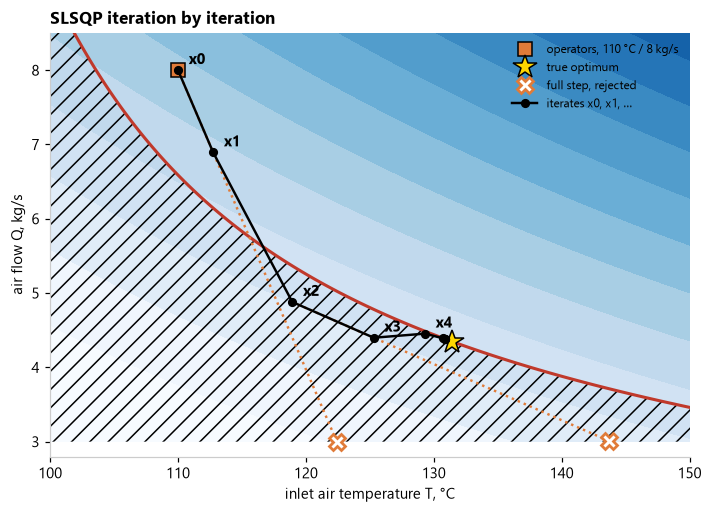

In [5]:
xs = np.array(f_slsqp.xs)                # every call SLSQP made, in order
iterates, rejected, i = [], [], 0
while i < len(xs):
    nudged = i + 2 < len(xs) and np.abs(xs[i + 1:i + 3] - xs[i]).max() < 1e-6
    if nudged:                           # a point and two nudged copies: an iterate
        iterates.append(xs[i])
        i += 3
    else:                                # a point alone: a full step that was shortened
        rejected.append((iterates[-1], xs[i]))
        i += 1
iterates = np.array(iterates)

path = pd.DataFrame(iterates, columns=["T", "Q"])
path["moisture, %"], path["power, kW"] = dryer(path["T"], path["Q"])
print(path.round(3).to_string())
print(f"\n{len(iterates)} iterates x 3 calls + {len(rejected)} rejected full steps "
      f"= {len(xs)} calls")
for start, x in rejected:
    moisture = dryer(*x)[0]
    print(f"rejected full step to T = {x[0]:.2f}, Q = {x[1]:.2f}: "
          f"moisture {moisture:.2f} %")

fig, ax = plt.subplots(figsize=(7.5, 5))
draw_map(ax, "SLSQP iteration by iteration")
for j, (start, x) in enumerate(rejected):
    ax.plot([start[0], x[0]], [start[1], x[1]], ":", color=ORANGE)
    label = "full step, rejected" if j == 0 else None       # one legend entry
    ax.plot(*x, "X", color="white", mec=ORANGE, mew=1.8, ms=10, label=label)
ax.plot(iterates[:, 0], iterates[:, 1], "-o", color="black", ms=5,
        label="iterates x0, x1, ...")
for k, (t, q) in enumerate(iterates[:5]):
    ax.annotate(f"x{k}", (t, q), textcoords="offset points", xytext=(7, 4),
                fontweight="bold")
ax.set(xlim=(100, 150), ylim=(2.8, 8.5))
ax.legend(loc="upper right", fontsize=8)
plt.show()

- The first step. With $\mathbf{B}_0 = \mathbf{I}$ the bowl is round and knows nothing about the
  scale of the problem, and the air flow is the most expensive setpoint, so the full step runs to
  the corner $Q = 3$. The real moisture there is 8.9 %. The line search cuts the step to 22 % of
  its length, and $\mathbf{x}_1$ lies on the dotted line. The same happens once more between
  $\mathbf{x}_2$ and $\mathbf{x}_3$.
- $\mathbf{x}_2$ to $\mathbf{x}_4$ are out of spec, at 3.84, 3.76 and 3.06 %. SLSQP only has to
  end in spec. On the way it obeys the straight-line guess of the red line, and the real line is
  curved.
- From $\mathbf{x}_4$ on, $\mathbf{B}$ knows the curvature and every step adds digits: the
  moisture misses 3.0 % by 0.06, then 0.004, then 0.00005.

SLSQP needs smooth functions, exact values and a reasonable start. Part 5 takes away the good
start, Part 6 the exact values, and the forest of Practice 5 the smoothness.

---

# Part 3. Nelder–Mead and the penalty

Nelder–Mead uses no slopes. It keeps a simplex of $n + 1$ points (a triangle here), sorted so
that $f(\mathbf{x}_1) \le \dots \le f(\mathbf{x}_{n+1})$, and moves the worst corner along the
line through the centre of the others, $\bar{\mathbf{x}} = \frac{1}{n} \sum_{i=1}^{n} \mathbf{x}_i$:

| move | trial point | kept when |
|---|---|---|
| reflect | $\mathbf{x}_r = \bar{\mathbf{x}} + (\bar{\mathbf{x}} - \mathbf{x}_{n+1})$ | $f(\mathbf{x}_1) \le f(\mathbf{x}_r) < f(\mathbf{x}_n)$ |
| expand | $\mathbf{x}_e = \bar{\mathbf{x}} + 2(\bar{\mathbf{x}} - \mathbf{x}_{n+1})$ | $\mathbf{x}_r$ beat $\mathbf{x}_1$; the better of $\mathbf{x}_e$, $\mathbf{x}_r$ |
| contract | $\mathbf{x}_c = \bar{\mathbf{x}} \pm \frac{1}{2}(\bar{\mathbf{x}} - \mathbf{x}_{n+1})$ | $\mathbf{x}_r$ no better than $\mathbf{x}_n$; kept if it helps |
| shrink | $\mathbf{x}_i \leftarrow \mathbf{x}_1 + \frac{1}{2}(\mathbf{x}_i - \mathbf{x}_1)$ | nothing else worked |

The triangle feels the slope with its corners. The worst corner is on the uphill side, so the
triangle flips away from it. A flip that works very well is stretched further (expand), one that
fails is pulled back in (contract), and when nothing works the triangle shrinks around its best
corner. It stops when the corners and their values are close (`xatol`, `fatol`) or after $200n$
calls.

Nelder–Mead knows nothing about constraints, so we add a **penalty**, $w$ kW for every percent
above the spec:

$$f_w(\mathbf{x}) = P(\mathbf{x}) + w \cdot \max\bigl(0,\ M(\mathbf{x}) - 3.0\bigr).$$

We take $w$ = 10 000 kW per %, `W` in the code. Every penalised method in Parts 3–6 uses this
weight, so they all minimise the same function.

Nelder-Mead, w = 10 000: T = 123.0 °C, Q = 4.97 kg/s, power 949 kW, moisture 3.00 %, 400 calls


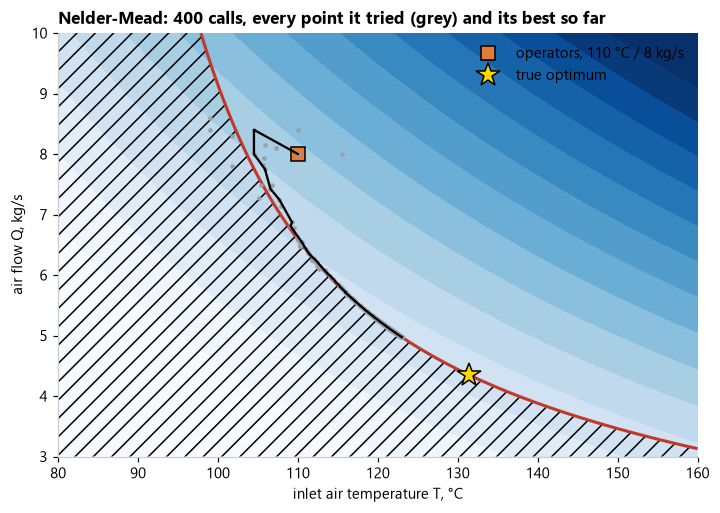

In [6]:
W = 1e4                     # kW per % above the spec, for every penalised method


def penalised_power(T, Q, r=0.0, w=W):
    # f_w: power plus w kW for every % of moisture above the spec. Arrays work too.
    m, p = dryer(T, Q, r=r)
    return p + w * np.maximum(0.0, m - SPEC)


def penalised(w=W):
    # f_w as a function of x = [T, Q], the form the optimisers want
    return lambda x: float(penalised_power(x[0], x[1], w=w))


f_nm = Counter(penalised())
res = minimize(f_nm, x0=[110, 8], method="Nelder-Mead", bounds=BOUNDS,
               options={"xatol": 0.01, "fatol": 0.01})
print(f"Nelder-Mead, w = 10 000: T = {res.x[0]:.1f} °C, Q = {res.x[1]:.2f} kg/s, "
      f"power {power(res.x):.0f} kW, moisture {SPEC - spec_margin(res.x):.2f} %, "
      f"{f_nm.calls} calls")

xs = np.array(f_nm.xs)
vals = np.array([f_nm.fun(x) for x in xs])
# after each call, the best point so far
best_so_far = [np.argmin(vals[:k + 1]) for k in range(len(xs))]
best_path = xs[best_so_far]

fig, ax = plt.subplots(figsize=(7.5, 5))
draw_map(ax, f"Nelder-Mead: {f_nm.calls} calls, every point it tried (grey) "
             "and its best so far")
ax.plot(xs[:, 0], xs[:, 1], ".", color=GREY, ms=4)
ax.plot(best_path[:, 0], best_path[:, 1], "-", color="black", lw=1.5)
ax.legend(loc="upper right")
plt.show()

The simplex runs down to the red line and then creeps along it. After 400 calls it stops 6 kW
short of the optimum that SLSQP found in 29. The penalty puts a crease along the line: the
function is smooth on either side and has a kink on the line itself. A triangle sliding along a
crease keeps poking a corner across it, the penalty throws that corner back, and so the triangle
has to stay narrow and take tiny steps.

## 3.1 Iteration by iteration

To watch the triangle, the next cell writes out scipy's algorithm: the same start (+5 % on each
coordinate), the same moves, the same clipping to the box. It makes exactly the same calls as
`minimize` above.

In [7]:
def nelder_mead(fun, x0, max_calls, xatol=0.01, fatol=0.01):
    # scipy's Nelder-Mead written out. fun is a Counter;
    # returns the history of the triangle.
    lo, hi = np.array(BOUNDS).T
    sim = np.array([x0, [x0[0] * 1.05, x0[1]], [x0[0], x0[1] * 1.05]], float)
    fs = np.array([fun(x) for x in sim])
    history = []
    while fun.calls < max_calls:
        # sort the corners, best first; stop when the triangle is small and flat
        order = np.argsort(fs)
        sim, fs = sim[order], fs[order]
        small = np.abs(sim[1:] - sim[0]).max() <= xatol
        flat = np.abs(fs[1:] - fs[0]).max() <= fatol
        if small and flat:
            break

        worst = sim[-1].copy()
        centre = sim[:-1].mean(axis=0)
        step = {"before": sim.copy(), "f_before": fs.copy(),
                "centre": centre, "tried": []}

        def trial(x):
            x = np.clip(x, lo, hi)
            step["tried"].append(x)
            return x, fun(x)

        # new is the point that replaces the worst corner; None means shrink
        xr, fr = trial(2 * centre - worst)                  # reflect
        if fr < fs[0]:
            # better than the best: try to go further
            xe, fe = trial(3 * centre - 2 * worst)
            if fe < fr:
                new, f_new, move = xe, fe, "expand"
            else:
                new, f_new, move = xr, fr, "reflect"
        elif fr < fs[-2]:
            # better than the second worst
            new, f_new, move = xr, fr, "reflect"
        elif fr < fs[-1]:
            # between the second worst and the worst: contract outside
            xc, fc = trial(1.5 * centre - 0.5 * worst)
            if fc <= fr:
                new, f_new, move = xc, fc, "contract outside"
            else:
                new, f_new, move = None, None, "shrink"
        else:
            # no better than the worst: contract inside
            xc, fc = trial(0.5 * centre + 0.5 * worst)
            if fc < fs[-1]:
                new, f_new, move = xc, fc, "contract inside"
            else:
                new, f_new, move = None, None, "shrink"

        if new is None:
            # shrink towards the best corner
            sim[1:] = np.clip(sim[0] + 0.5 * (sim[1:] - sim[0]), lo, hi)
            fs[1:] = [fun(x) for x in sim[1:]]
        else:
            sim[-1], fs[-1] = new, f_new
        step.update(move=move, after=sim.copy(), f_after=fs.copy())
        history.append(step)
    return history


mine = Counter(penalised())
history = nelder_mead(mine, [110, 8], max_calls=400)
same_calls = np.allclose(mine.xs[:400], f_nm.xs)
print(f"the same 400 calls as scipy: {same_calls}, {len(history)} iterations\n")
print(pd.Series([h["move"] for h in history]).value_counts().to_string())
print()
for k in [0, 20, 70, len(history) - 1]:
    h = history[k]
    width = np.ptp(h["after"][:, 0])
    print(f"after iteration {k + 1:3d}: width of the triangle in T {width:6.3f} °C, "
          f"best value {h['f_after'].min():7.1f}")

the same 400 calls as scipy: True, 212 iterations

reflect             76
contract inside     66
expand              56
contract outside    14

after iteration   1: width of the triangle in T  5.500 °C, best value  1150.1
after iteration  21: width of the triangle in T  1.626 °C, best value   986.0
after iteration  71: width of the triangle in T  0.033 °C, best value   954.0
after iteration 212: width of the triangle in T  0.034 °C, best value   948.9


             worst corner  its value                    trial points             move
iteration                                                                            
1          (115.50, 8.00)  1,243.400   (104.50, 8.40), (99.00, 8.60)          reflect
2          (110.00, 8.40)  1,221.900  (104.50, 8.00), (101.75, 7.80)          reflect
3          (110.00, 8.00)  1,174.100   (99.00, 8.40), (107.25, 8.10)  contract inside
4          (107.25, 8.10)  1,151.100  (101.75, 8.30), (105.88, 8.15)  contract inside
5          (104.50, 8.40)  1,150.100  (105.88, 7.75), (106.56, 7.43)           expand
6          (105.88, 8.15)  1,139.300  (105.19, 7.28), (105.70, 7.93)  contract inside
7          (105.70, 7.93)  1,112.200  (105.36, 7.49), (105.62, 7.82)  contract inside
8          (104.50, 8.00)  1,104.900  (107.68, 7.25), (109.27, 6.87)           expand


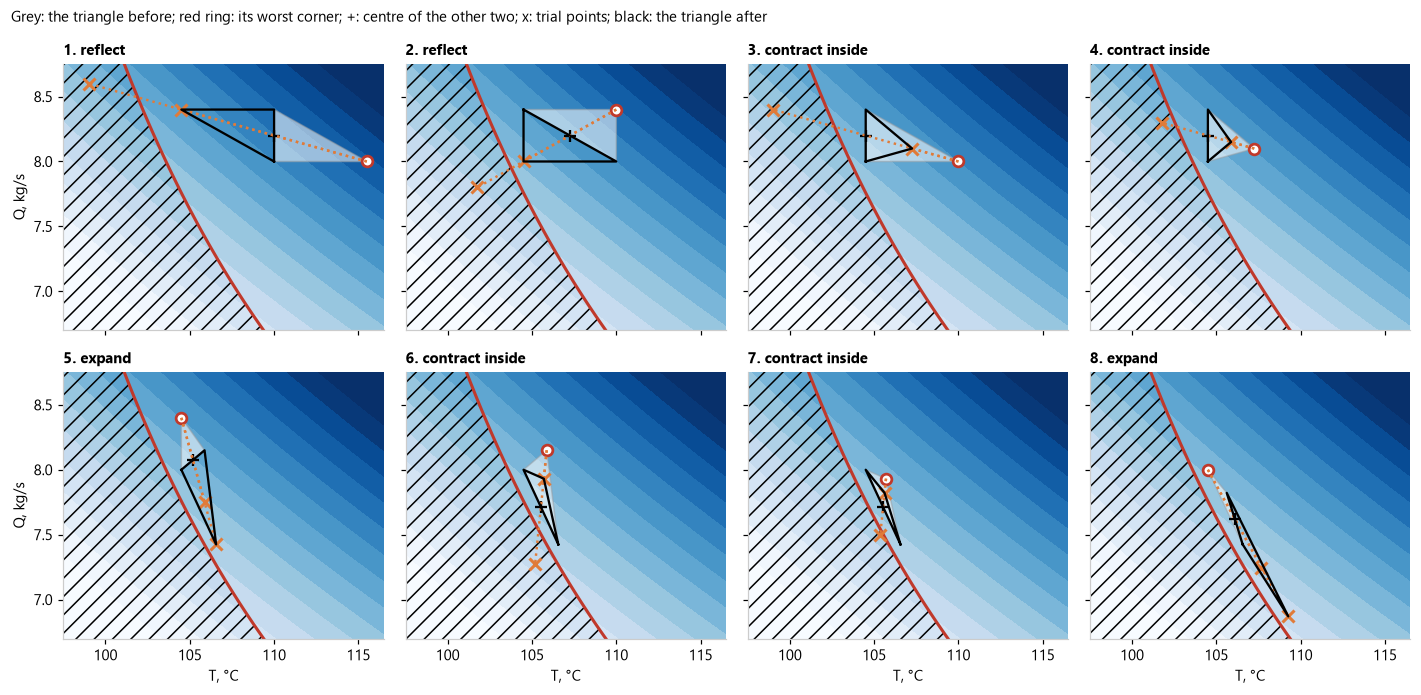

In [8]:
def pt(x):
    return f"({x[0]:.2f}, {x[1]:.2f})"


rows = []
for k, h in enumerate(history[:8]):
    rows.append({"iteration": k + 1,
                 "worst corner": pt(h["before"][-1]),
                 "its value": h["f_before"][-1],
                 "trial points": ", ".join(pt(t) for t in h["tried"]),
                 "move": h["move"]})
print(pd.DataFrame(rows).set_index("iteration").round(1).to_string())

power_levels = np.arange(950, 1301, 25)
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4), sharex=True, sharey=True)
for k, (ax, h) in enumerate(zip(axes.flat, history)):
    ax.contourf(tg, qg, P_map, levels=power_levels, cmap="Blues", extend="both")
    ax.contour(tg, qg, M_map, levels=[SPEC], colors=RED, linewidths=2)
    ax.contourf(tg, qg, M_map, levels=[SPEC, 100], colors="none", hatches=["//"])

    # the triangle before, its worst corner, the centre of the other two
    before = h["before"]
    worst = before[-1]
    ax.fill(before[:, 0], before[:, 1], color="white", alpha=0.55, ec=GREY)
    ax.plot(*worst, "o", color="white", mec=RED, mew=1.8, ms=7)
    ax.plot(*h["centre"], "+", color="black", ms=8, mew=1.5)

    # the trial points, and the triangle after the move
    for t in h["tried"]:
        ax.plot([worst[0], t[0]], [worst[1], t[1]], ":", color=ORANGE)
        ax.plot(*t, "x", color=ORANGE, ms=8, mew=2)
    after = np.vstack([h["after"], h["after"][:1]])
    ax.plot(after[:, 0], after[:, 1], "-", color="black", lw=1.5)

    ax.set_title(f"{k + 1}. {h['move']}", fontsize=10)
    ax.set(xlim=(97.5, 116.5), ylim=(6.7, 8.75))
    ax.grid(False)
for ax in axes[1]:
    ax.set(xlabel="T, °C")
for ax in axes[:, 0]:
    ax.set(ylabel="Q, kg/s")

title = ("Grey: the triangle before; red ring: its worst corner; "
         "+: centre of the other two; x: trial points; black: the triangle after")
fig.suptitle(title, fontsize=10, x=0.01, ha="left")
fig.tight_layout()
plt.show()

- Panels 1–2: far from the line, the triangle flips over whole and walks down the power.
- Panels 3, 4, 6 and 7: the reflection lands across the red line, the penalty throws it back,
  and the triangle contracts.
- Panels 5 and 8: expansions along the line.

The move counts above cover the whole run, and there is no shrink in it. Contractions alone make
the triangle narrow across the line, and a narrow triangle moves along the line in narrow steps.
By iteration 71 it is 0.03 °C wide, and the remaining 141 iterations gain only 5 kW.

**Can Nelder–Mead stop at a point that is not a minimum, on a smooth convex function?**

<details><summary>Answer</summary>

Yes. K. I. M. McKinnon (SIAM J. Optim., 1998) gave a function of two variables,

$$f(x, y) = \begin{cases} 360\,x^2 + y + y^2, & x \le 0,\\ 6\,x^2 + y + y^2, & x > 0,\end{cases}$$

strictly convex, with a continuous gradient and the minimum $f = -0.25$ at $(0, -0.5)$. Start
the triangle at $(0, 0)$, $(1, 1)$ and $\big((1+\sqrt{33})/8,\ (1-\sqrt{33})/8\big)$. Every
iteration is then an inside contraction: the corner $(0, 0)$ stays the best, and the other two
slide towards it while the triangle flattens along the $x$ axis. The method converges to
$(0, 0)$, where the gradient is $(0, 1)$, so the point is not even stationary. Nelder–Mead has
no step that guarantees descent, and a flat triangle cannot see the slope across it. The usual
cure is a restart with a fresh triangle at the answer. The cell below runs scipy on it.

</details>

In [9]:
def mckinnon(v):
    # McKinnon's function with tau = 2, theta = 6, phi = 60
    x, y = v
    steep = 360 if x <= 0 else 6
    return steep * x ** 2 + y + y ** 2


s33 = np.sqrt(33)
triangle = np.array([[0.0, 0.0], [1.0, 1.0], [(1 + s33) / 8, (1 - s33) / 8]])
tight = {"xatol": 1e-8, "fatol": 1e-8}

stuck = minimize(mckinnon, triangle[0], method="Nelder-Mead",
                 options={"initial_simplex": triangle, **tight})
restarted = minimize(mckinnon, stuck.x, method="Nelder-Mead", options=tight)

for name, r in [("from McKinnon's triangle", stuck), ("restarted from there", restarted)]:
    print(f"{name:24s}  x = {np.round(r.x, 6)}, f = {r.fun:.4f}, {r.nfev} calls")

from McKinnon's triangle  x = [0. 0.], f = 0.0000, 219 calls
restarted from there      x = [ 0.  -0.5], f = -0.2500, 181 calls


What if the penalty is cheap?

In [10]:
by_weight = {}
for w in [1, 30, 300, W]:
    r = minimize(penalised(w), x0=[110, 8], method="Nelder-Mead", bounds=BOUNDS,
                 options={"xatol": 0.01, "fatol": 0.01})
    m, p = dryer(*r.x)
    by_weight[w] = {"T, °C": r.x[0], "Q, kg/s": r.x[1],
                    "moisture, %": float(m), "power, kW": float(p)}
pd.DataFrame(by_weight).T.rename_axis("w, kW per %").round(2)

,"T, °C","Q, kg/s","moisture, %","power, kW"
"w, kW per %",,,,
1.000,80.000,3.000,18.790,413.300
30.000,109.890,3.490,9.830,669.740
300.000,130.630,4.400,3.000,942.510
"10,000.000",123.010,4.970,3.000,948.860


With $w = 1$ the optimiser ships 19 % moisture from the coldest corner, and with $w = 30$ still
10 %. From $w = 300$ on, the answer is on the line. The border between 30 and 300 has a reason.
Step over the line by $\delta$ % of moisture:

$$f_w \approx P^* - \lambda\,\delta + w\,\delta = P^* + (w - \lambda)\,\delta, \qquad \lambda = 66.8.$$

Crossing the line saves $\lambda$ kW per percent and costs $w$. If $w < \lambda$, breaking the
spec pays. If $w > \lambda$, the minimum of $f_w$ is the true optimum. This is the **exact
penalty** theorem: every weight above the shadow price gives the same answer, so $w$ only has to
be large enough. A squared penalty $w \max(0, M - 3.0)^2$ has no crease, but a small violation
costs it almost nothing, so its optimum always lands over the line, by $\delta = \lambda / (2w)$.

On a plant, $w$ is the price of off-spec product. Always print the constraint at the answer: an
optimiser never complains that the spec is broken.

---

# Part 4. Differential evolution

A population of $N$ = `popsize` $\times\, n$ points. Each generation, for every member
$\mathbf{x}_i$:

| step | formula |
|---|---|
| mutation (scipy default `best1bin`) | $\mathbf{v} = \mathbf{x}_{\text{best}} + F\,(\mathbf{x}_{r_1} - \mathbf{x}_{r_2})$, $F$ uniform in $[0.5, 1)$ |
| crossover | $u_j = v_j$ with probability $CR = 0.7$, else $x_{i,j}$; at least one $j$ from $\mathbf{v}$ |
| selection | $\mathbf{x}_i \leftarrow \mathbf{u}$ if $f(\mathbf{u}) \le f(\mathbf{x}_i)$ |

The step $F\,(\mathbf{x}_{r_1} - \mathbf{x}_{r_2})$ is the gap between two members. While the
population is spread out, the gaps are long and the method explores. Once the population has
gathered in a valley, the gaps and the steps shrink, and it refines. Nobody sets a step size: the
spread of the population sets it. $G$ generations cost $N(G + 1)$ calls. Week 10 adds two
relatives, the genetic algorithm and particle swarm.

We keep the penalty, so that every method in Part 5 solves the same function. `vectorized=True`
passes the whole population at once, which lets us photograph it.

DE: T = 130.9 °C, Q = 4.38 kg/s, power 943 kW, moisture 3.00 %
55 generations, 1120 calls to the plant


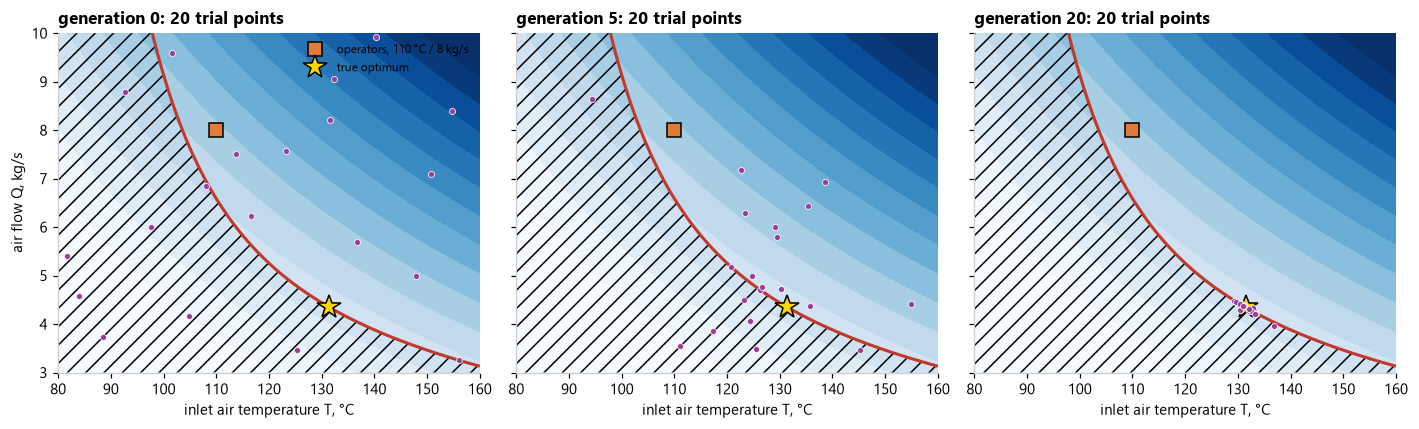

In [11]:
snapshots = []            # one array per generation: the trial points DE evaluated


def pen_population(X):
    # X has shape (2, population size): DE passes the whole generation at once
    snapshots.append(X.T.copy())
    return penalised_power(X[0], X[1])


res = differential_evolution(pen_population, BOUNDS, seed=1, popsize=10, tol=1e-6,
                             vectorized=True, updating="deferred", polish=False)
n_calls = sum(len(s) for s in snapshots)
print(f"DE: T = {res.x[0]:.1f} °C, Q = {res.x[1]:.2f} kg/s, power {power(res.x):.0f} kW, "
      f"moisture {SPEC - spec_margin(res.x):.2f} %")
print(f"{res.nit} generations, {n_calls} calls to the plant")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, g in zip(axes, [0, 5, min(20, len(snapshots) - 1)]):
    trial = snapshots[g]
    draw_map(ax, f"generation {g}: {len(trial)} trial points")
    ax.plot(trial[:, 0], trial[:, 1], "o", color=PURPLE, ms=4, mec="white", mew=0.5)
    if g:
        ax.set(ylabel="")
axes[0].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

Generation 0 covers the box. By generation 5 the population has left the expensive corners and
the out-of-spec region, and by generation 20 it lies along the red line. The answer is SLSQP's, at
$20 \times 56 = 1120$ calls, forty times more. On a smooth problem in two variables that is a bad
trade. Part 5 shows when it is a good one.

---

# Part 5. One more setpoint, the same budget

Open the recirculation damper, $r$ from 0 to 0.7. Recirculated air is warm, which saves gas, but
it is also wet, which slows the drying. With three setpoints there is no map any more.

Every method gets **125 calls**: a 5 × 5 × 5 grid, 125 random points, Nelder–Mead from the
operators' point, and DE with a small population. Random search and DE run with 20 seeds. The
code cuts every method's record at call 125, so none of them gets more.

In [12]:
BOUNDS3 = [(T_LO, T_HI), (Q_LO, Q_HI), (0.0, 0.7)]
BUDGET = 125
lo3, hi3 = np.array(BOUNDS3).T


def pen3(x):
    return float(penalised_power(x[0], x[1], r=x[2]))


curves, ends = {}, {}                    # method -> one entry per run


def record(name, xs):
    # Keep a run: its best-so-far curve and its best point,
    # both within the first BUDGET calls.
    xs = np.asarray(xs)[:BUDGET]
    vals = np.array([pen3(x) for x in xs])
    curves.setdefault(name, []).append(np.minimum.accumulate(vals))
    ends.setdefault(name, []).append(xs[np.argmin(vals)])


levels = [np.linspace(lo, hi, 5) for lo, hi in BOUNDS3]
grid = np.array(np.meshgrid(*levels, indexing="ij")).reshape(3, -1).T
record("grid 5 x 5 x 5", grid)

for seed in range(20):
    uniform = np.random.default_rng(seed).random((BUDGET, 3))
    record("random", lo3 + (hi3 - lo3) * uniform)

    f_de = Counter(pen3)
    differential_evolution(f_de, BOUNDS3, seed=seed, popsize=3, maxiter=200, tol=0,
                           polish=False, init="sobol")
    record("DE", f_de.xs)

f_nm3 = Counter(pen3)
minimize(f_nm3, x0=[110, 8, 0.0], method="Nelder-Mead", bounds=BOUNDS3,
         options={"maxfev": BUDGET})
record("Nelder-Mead", f_nm3.xs)

truth = differential_evolution(pen3, BOUNDS3, seed=0, tol=1e-10, maxiter=1000)
T_true, Q_true, r_true = truth.x
print(f"true optimum (DE, no budget): T = {T_true:.1f} °C, Q = {Q_true:.2f} kg/s, "
      f"r = {r_true:.2f}, power {truth.fun:.1f} kW\n")

table = {}
for name, c in curves.items():
    final = np.array([cc[-1] for cc in c])
    final_r = np.array(ends[name])[:, 2]
    table[name] = {"runs": len(c),
                   "calls per run": max(len(cc) for cc in c),
                   "median power after 125 calls, kW": np.median(final),
                   "worst run, kW": final.max(),
                   "median r at the end": np.median(final_r)}
table = pd.DataFrame(table).T.astype({"runs": int, "calls per run": int})
table.rename_axis("method").round(2)

true optimum (DE, no budget): T = 155.7 °C, Q = 4.91 kg/s, r = 0.70, power 911.5 kW



,runs,calls per run,"median power after 125 calls, kW","worst run, kW",median r at the end
method,,,,,
grid 5 x 5 x 5,1,125,928.140,928.140,0.700
random,20,125,952.020,983.890,0.470
DE,20,125,932.310,957.970,0.640
Nelder-Mead,1,125,955.290,955.290,0.000


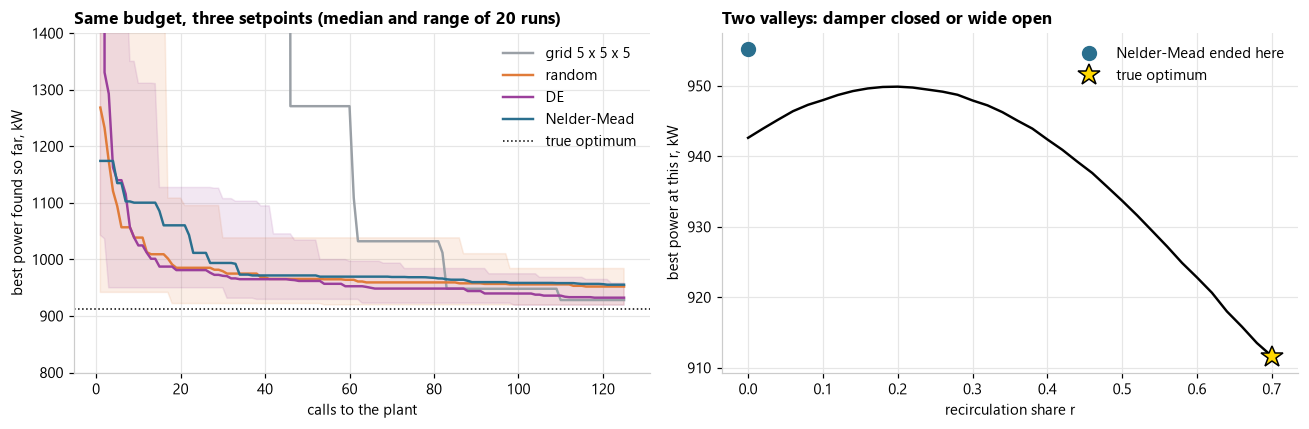

In [13]:
colors = {"grid 5 x 5 x 5": GREY, "random": ORANGE, "Nelder-Mead": BLUE, "DE": PURPLE}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
calls = np.arange(1, BUDGET + 1)
for name, c in curves.items():
    # a run that stopped early keeps its last value up to the budget
    c = np.array([np.pad(cc, (0, BUDGET - len(cc)), mode="edge") for cc in c])
    ax.plot(calls, np.median(c, axis=0), color=colors[name], label=name)
    if len(c) > 1:
        ax.fill_between(calls, c.min(0), c.max(0), color=colors[name], alpha=0.12)
ax.axhline(truth.fun, color="black", ls=":", lw=1, label="true optimum")
ax.set(ylim=(800, 1400), xlabel="calls to the plant",
       ylabel="best power found so far, kW")
ax.set_title("Same budget, three setpoints (median and range of 20 runs)", fontsize=11)
ax.legend()

# the best power for each damper position, T and Q optimised for it by brute force
rs = np.linspace(0, 0.7, 36)
prof = []
for r_ in rs:
    m, p = dryer(tg, qg, r=r_)
    prof.append(np.min(np.where(m <= SPEC, p, np.inf)))
ax = axes[1]
ax.plot(rs, prof, color="black")
ax.set(xlabel="recirculation share r", ylabel="best power at this r, kW")
ax.set_title("Two valleys: damper closed or wide open", fontsize=11)
nm_end = ends["Nelder-Mead"][0]
ax.plot(nm_end[2], pen3(nm_end), "o", color=BLUE, ms=9, label="Nelder-Mead ended here")
ax.plot(r_true, truth.fun, "*", color="gold", ms=15, mec="black", label="true optimum")
ax.legend()
fig.tight_layout()
plt.show()

The right panel gives the best power for each damper position, with $T$ and $Q$ found by brute
force. There are two valleys, damper closed and damper wide open, with a ridge between them.

| method | what happened |
|---|---|
| Nelder–Mead | started with the damper closed and stayed in the near valley. Its triangle only compares neighbouring points, and near $r = 0$ opening the damper a little makes things worse |
| grid | best here, because the optimum is on the edge of the box ($r = 0.7$) and a grid always tries the edges |
| random | between the two, with a wide spread from run to run |
| DE | the far valley in most runs (median $r$ 0.64), median 2.3 % above the optimum |

## 5.1 What a budget buys

- A grid with $L$ levels per setpoint costs $L^n$ calls, with step $(u_j - l_j)/(L - 1)$. A
  budget $B$ buys $L = B^{1/n}$ levels: 125 calls are 11 levels in 2D, 5 in 3D, 3 in 4D. Every
  added setpoint makes the grid coarser on all the others.
- Random search: if the good region is a share $p$ of the box, the chance of at least one hit is
  $1 - (1 - p)^B$. For $p$ = 1 % and $B = 125$ it is 0.72. The dimension enters through $p$: a
  region that spans 10 % of the range of every setpoint is a share $p = 0.1^n$ of the box.

---

# Part 6. No simulator: the historian

On the real dryer there is no `dryer()`. There is the **historian**: three months of hourly $T$,
$Q$ and lab moisture. Power has a formula; moisture does not, so we learn it from the data. A
model fitted to data and used in place of the plant is a **surrogate**.

- The operators kept near 110 °C and 8 kg/s, so the data cover a small patch of the map.
- The feed moisture drifted, and the lab is accurate to ±0.15 %. Neither the drift nor the lab
  error is in the data.
- The damper was never opened, so from here on $r = 0$.

In [14]:
def ar1(n, sigma, phi, rng):
    # A slowly wandering signal: each hour keeps phi of the last hour's deviation.
    x = np.zeros(n)
    x[0] = rng.normal(0, sigma)
    for t in range(1, n):
        x[t] = phi * x[t - 1] + rng.normal(0, sigma * np.sqrt(1 - phi ** 2))
    return x


def historian(hours, T0, Q0, sd_T, sd_Q, seed):
    # Hourly records of a dryer run around the setpoints (T0, Q0).
    rng = np.random.default_rng(seed)
    T = np.clip(T0 + ar1(hours, sd_T, 0.9, rng), T_LO, T_HI)
    Q = np.clip(Q0 + ar1(hours, sd_Q, 0.9, rng), Q_LO, Q_HI)
    m_in = 25 + ar1(hours, 0.8, 0.97, rng)                    # the feed: not recorded
    lab = dryer(T, Q, m_in)[0] + rng.normal(0, 0.15, hours)    # the lab result: recorded
    return pd.DataFrame({"T": T, "Q": Q, "moisture": lab})


hist = historian(2000, 110, 8, sd_T=4, sd_Q=0.4, seed=0)
print(hist.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())
print(f"\nhours out of spec: {(hist.moisture > SPEC).sum()} of {len(hist)}")

           T     Q  moisture
mean 109.510 8.000     2.070
std    4.010 0.400     0.710
min   97.690 6.900     0.390
max  123.310 9.200     4.660

hours out of spec: 215 of 2000


A **quadratic** surrogate in the standardised inputs $t$, $q$, fitted by least squares:

$$\hat M = \boldsymbol{\phi}(\mathbf{x})^{\top} \boldsymbol{\beta} = \beta_0 + \beta_1 t + \beta_2 q + \beta_3 t^2 + \beta_4\, t q + \beta_5 q^2, \qquad \hat{\boldsymbol{\beta}} = (\boldsymbol{\Phi}^{\top} \boldsymbol{\Phi})^{-1} \boldsymbol{\Phi}^{\top} \mathbf{y}.$$

$\boldsymbol{\Phi}$ ($N \times 6$) stacks the features of the records, and $\mathbf{y}$ holds the
lab results. Cross-validation says how well the surrogate predicts inside the data. About the
rest of the map it says nothing.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict


def make_surrogate():
    return make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression())


X_h = hist[["T", "Q"]].to_numpy()
y_h = hist["moisture"].to_numpy()
folds = KFold(5, shuffle=True, random_state=0)
oof = cross_val_predict(make_surrogate(), X_h, y_h, cv=folds)
rmse = np.sqrt(np.mean((oof - y_h) ** 2))
print(f"cross-validated error: RMSE {rmse:.3f} %, "
      f"against a spread of {y_h.std():.3f} % in the data")
surrogate = make_surrogate().fit(X_h, y_h)


def pen_surrogate(model):
    # f_w with the moisture predicted by the model instead of measured on the dryer
    def f(x):
        m = model.predict(np.atleast_2d(x))[0]
        return power(x) + W * max(0.0, m - SPEC)
    return f


res = differential_evolution(pen_surrogate(surrogate), BOUNDS, seed=0, tol=1e-10)
x_sur = res.x
m_pred = surrogate.predict([x_sur])[0]
m_true, p_true = dryer(*x_sur)
print(f"\noptimum of the surrogate: T = {x_sur[0]:.1f} °C, Q = {x_sur[1]:.2f} kg/s, "
      f"power {p_true:.0f} kW")
print(f"  moisture the surrogate promises: {m_pred:.2f} %")
print(f"  moisture the dryer delivers:     {m_true:.2f} %\n")

features = surrogate[:-1]                  # scaling and the quadratic terms
Phi = features.transform(X_h)              # the six features of every record, (N, 6)
s = np.sqrt(np.mean((surrogate.predict(X_h) - y_h) ** 2))
inv = np.linalg.inv(Phi.T @ Phi)
for name, x in [("operators' point", [110, 8]), ("surrogate's optimum", x_sur)]:
    phi = features.transform([x])[0]
    se = s * np.sqrt(phi @ inv @ phi)
    print(f"standard error of the surface at the {name}: {se:.3f} %")

cross-validated error: RMSE 0.245 %, against a spread of 0.715 % in the data



optimum of the surrogate: T = 126.4 °C, Q = 3.00 kg/s, power 731 kW
  moisture the surrogate promises: 3.00 %
  moisture the dryer delivers:     8.13 %

standard error of the surface at the operators' point: 0.008 %
standard error of the surface at the surrogate's optimum: 0.684 %


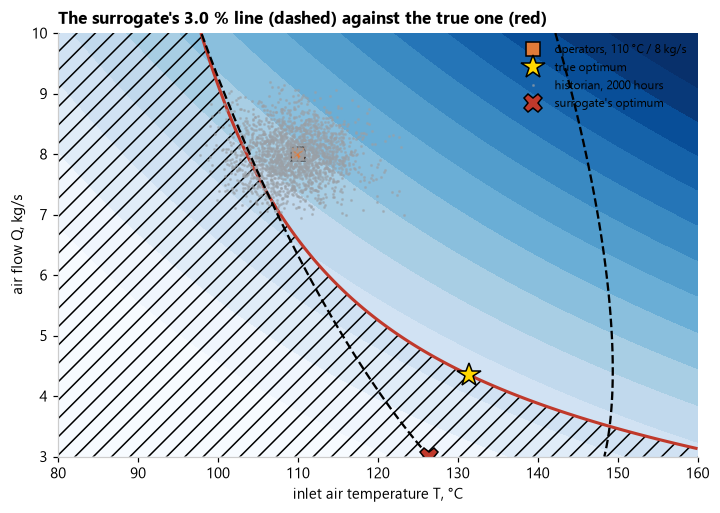

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5))
draw_map(ax, "The surrogate's 3.0 % line (dashed) against the true one (red)")
ax.plot(hist["T"], hist["Q"], ".", color=GREY, ms=2, alpha=0.5,
        label="historian, 2000 hours")
grid_points = np.c_[tg.ravel(), qg.ravel()]
m_sur_map = surrogate.predict(grid_points).reshape(tg.shape)
ax.contour(tg, qg, m_sur_map, levels=[SPEC], colors="black", linestyles="--",
           linewidths=1.5)
ax.plot(*x_sur, "X", color=RED, ms=12, mec="black", label="surrogate's optimum")
ax.legend(loc="upper right", fontsize=8)
plt.show()

Inside the grey cloud the surrogate is as good as the lab noise. Outside it, the surrogate's
3.0 % line wanders off, and the optimiser goes exactly there. An optimiser looks for the place
where the model is most optimistic, and a model's errors are largest, in either direction, where
it has no data. So the optimiser is drawn to the model's mistakes. The real dryer would deliver
8.1 %.

The noise part of the error at a point $\mathbf{x}$ is

$$\mathrm{se}(\mathbf{x}) = s \sqrt{\boldsymbol{\phi}(\mathbf{x})^{\top} (\boldsymbol{\Phi}^{\top} \boldsymbol{\Phi})^{-1} \boldsymbol{\phi}(\mathbf{x})}:$$

0.008 % at the operators' point, 0.68 % at the surrogate's optimum. It grows roughly as the square
of the distance from the data, because $\boldsymbol{\phi}$ contains squares. Even so it is
optimistic: it counts only the noise in the fitted coefficients and assumes the true surface is a
quadratic. It is not, and the real miss there is 5.1 %.

## 6.1 The trust region

Move in small steps and collect data at each one. Step $k$ solves

$$\min_{\mathbf{x}} P(\mathbf{x}) \quad \text{subject to} \quad \hat M_k(\mathbf{x}) \le 3.0, \quad |T - T_k| \le 8, \quad |Q - Q_k| \le 0.8,$$

with $\hat M_k$ fitted on the records near $\mathbf{x}_k$ (within 15 °C and 1.5 kg/s). Then the
dryer runs there for three days, and the records go into the data. The box is the trust region:
the step may go only as far as the surrogate can be believed. Classical methods also resize the
box by $\rho_k$ = actual improvement / predicted improvement: they grow it if $\rho_k > 0.75$ and
shrink it if $\rho_k < 0.25$. Ours stays fixed.

           T     Q  predicted, %  delivered, %  power, kW
step                                                     
0    110.000 8.000           NaN         1.850  1,174.140
1    106.740 7.200         3.000         3.030  1,042.300
2    109.550 6.400         3.000         3.300    984.080
3    113.300 5.600         3.000         3.650    931.830
4    115.280 5.800         3.000         3.000    974.240
5    115.230 5.850         3.000         2.940    979.760
6    115.920 5.780         3.000         2.910    979.110
7    117.640 5.640         3.000         2.820    979.150
8    121.320 5.260         3.000         2.790    969.120


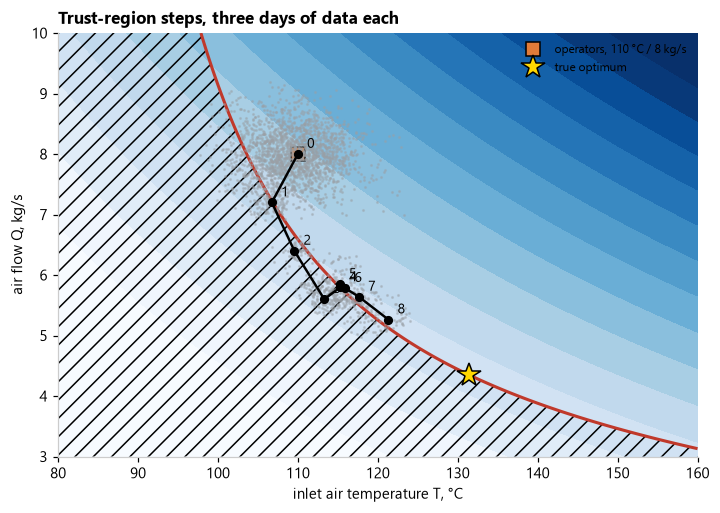

In [17]:
STEP_T, STEP_Q = 8.0, 0.8                # the trust region: how far one step may go
NEAR_T, NEAR_Q = 15.0, 1.5               # the records each local surrogate is fitted on

current = np.array([110.0, 8.0])
data = hist.copy()
steps = [{"step": 0, "T": 110.0, "Q": 8.0, "predicted, %": np.nan,
          "delivered, %": float(m0), "power, kW": float(p0)}]       # the operators' point
path = [current.copy()]

for step in range(1, 9):
    # a local surrogate, fitted on the records near the current setpoints
    near_T = abs(data["T"] - current[0]) <= NEAR_T
    near_Q = abs(data["Q"] - current[1]) <= NEAR_Q
    near = near_T & near_Q
    model = make_surrogate().fit(data.loc[near, ["T", "Q"]].to_numpy(),
                                 data.loc[near, "moisture"])

    # its optimum inside the trust region around the current setpoints
    box = [(max(T_LO, current[0] - STEP_T), min(T_HI, current[0] + STEP_T)),
           (max(Q_LO, current[1] - STEP_Q), min(Q_HI, current[1] + STEP_Q))]
    current = differential_evolution(pen_surrogate(model), box, seed=0, tol=1e-10).x
    m, p = dryer(*current)
    steps.append({"step": step, "T": current[0], "Q": current[1],
                  "predicted, %": model.predict([current])[0], "delivered, %": float(m),
                  "power, kW": float(p)})
    path.append(current.copy())

    # three days at the new setpoints go into the historian
    new_days = historian(72, current[0], current[1], 2, 0.2, seed=step)
    data = pd.concat([data, new_days], ignore_index=True)

steps = pd.DataFrame(steps).set_index("step")
print(steps.round(2).to_string())

path = np.array(path)
fig, ax = plt.subplots(figsize=(7.5, 5))
draw_map(ax, "Trust-region steps, three days of data each")
ax.plot(data["T"], data["Q"], ".", color=GREY, ms=2, alpha=0.4)
ax.plot(path[:, 0], path[:, 1], "o-", color="black", ms=5)
for k, (t, q) in enumerate(path):
    ax.annotate(str(k), (t, q), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.legend(loc="upper right", fontsize=8)
plt.show()

In three steps (nine days) the power falls from 1174 to about 930–980 kW, a few percent above the
true 943. Then the steps wander along the flat valley. The surrogate aims at 3.0 % every time; the
dryer delivers 2.8–3.65 % because of the lab noise and the unrecorded feed.

---

# Part 7. The safety margin

The optimiser puts you on the constraint, and there about half of the disturbances push you over
it. Below, the dryer runs for six weeks at the optimum while the feed drifts as in the historian.

In [18]:
rng = np.random.default_rng(7)
m_feed = 25 + ar1(1000, 0.8, 0.97, rng)  # six weeks of hourly feed moisture, %


def out_of_spec(T, Q):
    return np.mean(dryer(T, Q, m_feed)[0] > SPEC)


rows = []
for aim in [3.0, 2.8, 2.6, 2.4, 2.2]:
    # the cheapest grid point that meets the aim on the average feed
    k = np.argmin(np.where(M_map <= aim, P_map, np.inf))
    T_a, Q_a = tg.flat[k], qg.flat[k]
    rows.append({"aim, %": aim, "T, °C": T_a, "Q, kg/s": Q_a, "power, kW": P_map.flat[k],
                 "hours out of spec": out_of_spec(T_a, Q_a)})
rows.append({"aim, %": "operators", "T, °C": 110, "Q, kg/s": 8, "power, kW": p0,
             "hours out of spec": out_of_spec(110, 8)})
margin = pd.DataFrame(rows).set_index("aim, %")

print(f"feed moisture over the six weeks: mean {m_feed.mean():.2f} %, "
      f"std {m_feed.std():.2f} %")
for name, (T_, Q_) in [("true optimum", (T_best, Q_best)), ("operators", (110, 8))]:
    # dM/dm_in by a 1 % nudge of the feed
    dM = float(dryer(T_, Q_, 25.5)[0] - dryer(T_, Q_, 24.5)[0])
    scatter = dryer(T_, Q_, m_feed)[0].std()
    print(f"{name:12s}  dM/dm_in = {dM:.2f},  sigma_M = {dM * m_feed.std():.2f} %,  "
          f"scatter in the six weeks {scatter:.2f} %")
margin.round(3)

feed moisture over the six weeks: mean 24.52 %, std 0.89 %
true optimum  dM/dm_in = 0.46,  sigma_M = 0.41 %,  scatter in the six weeks 0.39 %
operators     dM/dm_in = 0.22,  sigma_M = 0.19 %,  scatter in the six weeks 0.18 %


,"T, °C","Q, kg/s","power, kW",hours out of spec
"aim, %",,,,
3.000,131.463,4.347,942.626,0.331
2.800,131.784,4.431,956.506,0.158
2.600,133.066,4.459,971.175,0.062
2.400,133.387,4.557,987.167,0.005
2.200,134.509,4.613,"1,004.520",0.000
operators,110.000,8.000,"1,174.142",0.000


Aiming at 3.0 % puts a third of the hours out of spec. Aiming at 2.4 % brings that down to half a
percent and still saves 187 of the 232 kW.

## 7.1 The margin in formulas

$$\sigma_M \approx \left|\frac{\partial M}{\partial m_{in}}\right| \sigma_{feed}, \qquad P(M > 3.0) = 1 - \Phi(z) \quad \text{when aiming at} \quad \mu = 3.0 - z\,\sigma_M.$$

- $\partial M / \partial m_{in}$ is 0.46 at the optimum and 0.22 at the operators' point. Near the
  optimum the dryer is short of heat, so a wetter feed goes almost straight through to the
  product. At the operators' point the dryer has heat to spare and absorbs more of it.
- $z$ = 0, 1.28, 1.64, 2.33 gives 50, 10, 5, 1 % out of spec. A constraint on the probability of
  a violation is called a **chance constraint**.
- To choose $z$, minimise the cost of an hour, $\lambda z \sigma_M + c\,(1 - \Phi(z))$. The first
  term is the margin, paid at the shadow price $\lambda$. The second is the price $c$ of an
  off-spec hour, in kW, times its probability. The derivative is zero where
  $\lambda \sigma_M = c\,\varphi(z)$, with $\varphi$ the normal density, which gives the formula
  below. It is the same reasoning as the threshold of Practice 3.

$$z^* = \sqrt{2 \ln \frac{c}{\sqrt{2\pi}\, \lambda\, \sigma_M}}$$

---

## Further reading

- Bayesian optimisation takes the surrogate of Part 6 one step further. It fits a Gaussian
  process to the calls made so far, which gives a prediction and its uncertainty at every
  untried setpoint, and puts the next call where an acquisition function, such as the
  expected improvement, is largest. It is built for budgets of tens of calls, where one call
  is a shift on the plant or an hour of simulation, and it loses its edge with many variables.
  The method in its usual form is D. R. Jones, M. Schonlau and W. J. Welch, "Efficient Global
  Optimization of Expensive Black-Box Functions", J. Global Optim. (1998).

## Where this goes next

Practice 5 optimises the recipe of concrete: a surrogate of its strength learned from 1030 lab
tests, and the mix with the least embodied energy that reaches the required strength. There is
no simulator there, so you decide how far the optimum can be trusted.